# Static TOF vs Photon Energy

This notebook loads the shot-resolved `run*_static_tof.h5` file produced by `compute_static_tof.py` and analyses the electron TOF scan as a function of nominal photon energy.

The file stores raw per-shot `tofs_e` and `gmd`, so we can:

- histogram the spectra after loading,
- normalise rigorously to GMD,
- inspect shot counts and train counts,
- make post-hoc GMD-bin diagnostics for a selected energy.


In [102]:
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

%matplotlib inline

cwd = Path.cwd().resolve()
repo_root = None
for p in [cwd] + list(cwd.parents):
    if (p / 'analysis' / 'scripts').exists():
        repo_root = p
        break
if repo_root is None:
    raise RuntimeError('Could not locate repository root.')
sys.path.insert(0, str(repo_root / 'analysis' / 'scripts'))

import config as path_config


In [103]:
RUN_NO = 58873
INPUT_H5 = Path(path_config.COMBINED_DIR).parent / 'tof_static' / f'run{RUN_NO}_static_tof.h5'

TOF_XLIM = (0, 5000)
TOF_REBIN = 4                # try 1, 4, 8 ... for smoother maps
TOF_ROI = (1700, 2100)
LINEOUT_ENERGIES = None      # e.g. [279.0, 283.0, 288.0]
LINEOUT_AUTO_COUNT = 5
SELECTED_ENERGY = 283.0
GMD_N_BINS = 6

if not INPUT_H5.exists():
    tof_static_dir = Path(path_config.COMBINED_DIR).parent / 'tof_static'
    print(f'Expected file not found: {INPUT_H5}')
    print(f'Looked in: {tof_static_dir}')
    if tof_static_dir.exists():
        candidates = sorted(tof_static_dir.glob('run*_static_tof.h5'))
        print('Available files:')
        for p in candidates:
            print(f'  {p.name}')
    raise FileNotFoundError(INPUT_H5)


In [104]:
with h5py.File(INPUT_H5, 'r') as f:
    tofs_e = f['tofs_e'][...]
    gmd = f['gmd'][...]
    train_id = f['train_id'][...]
    bunch_index = f['bunch_index'][...]
    n_shots = f['n_shots'][...]
    n_selected_trains = f['n_selected_trains'][...]
    nominal_energies = f['nominal_energies'][...]
    tof_edges = f['tof_edges'][...]
    signal_bunch_indices = f['signal_bunch_indices'][...]
    input_h5_paths = f['input_h5_paths'][...] if 'input_h5_paths' in f else None
    attrs = dict(f.attrs)

if input_h5_paths is not None:
    input_h5_paths = [p.decode() if isinstance(p, bytes) else str(p) for p in input_h5_paths]


In [105]:
def energy_edges(energies):
    energies = np.asarray(energies, dtype=np.float64)
    if energies.size == 1:
        return np.array([energies[0] - 0.5, energies[0] + 0.5], dtype=np.float64)
    mids = 0.5 * (energies[:-1] + energies[1:])
    first = energies[0] - (mids[0] - energies[0])
    last = energies[-1] + (energies[-1] - mids[-1])
    return np.r_[first, mids, last]


def pick_energy_indices(energies, requested=None, max_auto=5):
    energies = np.asarray(energies, dtype=np.float64)
    if requested is None:
        if energies.size <= max_auto:
            return np.arange(energies.size, dtype=int)
        return np.unique(np.round(np.linspace(0, energies.size - 1, max_auto)).astype(int))
    idx = [int(np.abs(energies - e).argmin()) for e in requested]
    return np.unique(np.asarray(idx, dtype=int))


def fmt_energy(e):
    return f'{float(e):.1f} eV'


def rebin_last_axis(arr, factor):
    arr = np.asarray(arr, dtype=np.float64)
    factor = int(factor)
    if factor <= 1:
        return arr.copy()
    n_bins = arr.shape[-1]
    starts = np.arange(0, n_bins, factor, dtype=int)
    out = np.empty(arr.shape[:-1] + (starts.size,), dtype=np.float64)
    for i, s in enumerate(starts):
        out[..., i] = np.nansum(arr[..., s:min(s + factor, n_bins)], axis=-1)
    return out


def rebin_edges(edges, factor):
    edges = np.asarray(edges, dtype=np.float64)
    factor = int(factor)
    if factor <= 1:
        return edges.copy()
    n_bins = edges.size - 1
    starts = np.arange(0, n_bins, factor, dtype=int)
    return np.r_[edges[starts], edges[-1]]


def mean_spectrum_per_shot(tofs_shot, tof_edges):
    n = int(tofs_shot.shape[0])
    if n == 0:
        return np.full(len(tof_edges) - 1, np.nan, dtype=np.float64)
    valid = tofs_shot != 0
    hits = tofs_shot[valid]
    hist, _ = np.histogram(hits, bins=tof_edges)
    return hist.astype(np.float64) / float(n)


def spectrum_over_gmd(tofs_shot, gmd_shot, tof_edges):
    gmd_shot = np.asarray(gmd_shot, dtype=np.float64)
    shot_ok = np.isfinite(gmd_shot) & (gmd_shot > 0)
    if not np.any(shot_ok):
        return np.full(len(tof_edges) - 1, np.nan, dtype=np.float64)
    valid = tofs_shot != 0
    hits = tofs_shot[valid]
    shot_of_hit = np.broadcast_to(np.arange(tofs_shot.shape[0])[:, None], tofs_shot.shape)[valid]
    keep = shot_ok[shot_of_hit]
    hist, _ = np.histogram(hits[keep], bins=tof_edges)
    return hist.astype(np.float64) / float(np.sum(gmd_shot[shot_ok]))


def counts_in_window_per_shot(tofs_shot, tof_min, tof_max):
    mask = (tofs_shot >= tof_min) & (tofs_shot < tof_max) & (tofs_shot != 0)
    return mask.sum(axis=1).astype(np.float64)


def percentile_bin_edges(x, n_bins):
    edges = np.percentile(x, np.linspace(0, 100, n_bins + 1))
    edges = np.asarray(edges, dtype=np.float64)
    keep = np.r_[True, np.diff(edges) > 0]
    return edges[keep]


tof_centers = 0.5 * (tof_edges[:-1] + tof_edges[1:])
energy_mesh = energy_edges(nominal_energies)
plot_tof_edges = rebin_edges(tof_edges, TOF_REBIN)
plot_tof_centers = 0.5 * (plot_tof_edges[:-1] + plot_tof_edges[1:])


In [106]:
N_E, N_shots_max, max_hits = tofs_e.shape
mean_gmd = np.full(N_E, np.nan, dtype=np.float64)

print(f'file               : {INPUT_H5}')
print(f'FLASH_ENV          : {path_config.FLASH_ENV}')
print(f'run                : {attrs.get("run_no")}')
print(f'input mode         : {attrs.get("input_mode")}')
print(f'background mode    : {attrs.get("background_mode")}')
print(f'energy points      : {N_E}')
print(f'energy range       : {nominal_energies[0]:.2f} .. {nominal_energies[-1]:.2f} eV')
print(f'shots max / energy : {N_shots_max}')
print(f'max hits / shot    : {max_hits}')
print(f'default eTOF bins  : {len(tof_centers)}  [{tof_edges[0]:.1f}, {tof_edges[-1]:.1f})')
print(f'plot eTOF bins     : {len(plot_tof_centers)}  rebin={TOF_REBIN}')
print(f'signal bunches     : {signal_bunch_indices[0]} .. {signal_bunch_indices[-1]}  ({len(signal_bunch_indices)} total)')
print(f'total shots        : {int(n_shots.sum())}')
print(f'trim start / end   : {attrs.get("trim_start")} / {attrs.get("trim_end")}')
print()
print(f'{"idx":>3s}  {"E (eV)":>8s}  {"shots":>8s}  {"trains":>8s}  {"<GMD>":>10s}  source')
print('-' * 90)
for i, energy in enumerate(nominal_energies):
    n = int(n_shots[i])
    g = gmd[i, :n]
    mean_gmd[i] = np.nanmean(g) if n > 0 else np.nan
    src = Path(input_h5_paths[i]).name if input_h5_paths is not None else '-'
    print(f'{i:3d}  {energy:8.2f}  {n:8d}  {int(n_selected_trains[i]):8d}  {mean_gmd[i]:10.5f}  {src}')


file               : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/tof_static/run58873_static_tof.h5
FLASH_ENV          : remote
run                : 58873
input mode         : per_energy_h5s
background mode    : none
energy points      : 10
energy range       : 279.00 .. 288.00 eV
shots max / energy : 662156
max hits / shot    : 50
default eTOF bins  : 1999  [0.0, 40000.0)
plot eTOF bins     : 500  rebin=4
signal bunches     : 0 .. 100  (101 total)
total shots        : 6142416
trim start / end   : 2 / 2

idx    E (eV)     shots    trains       <GMD>  source
------------------------------------------------------------------------------------------
  0    279.00    662156      6556     3.56459  glycine_WL_scan_279eV.h5
  1    280.00    609030      6030     3.24538  glycine_WL_scan_280eV.h5
  2    281.00    608929      6029     2.60227  glycine_WL_scan_281eV.h5
  3    282.00    609030      6030     1.84107  glycine_WL_scan_282eV.h5
  4    283.00    608828      6028     0.72392  gly

In [107]:
mean_spec = np.full((N_E, len(tof_centers)), np.nan, dtype=np.float64)
norm_spec = np.full((N_E, len(tof_centers)), np.nan, dtype=np.float64)

for i in range(N_E):
    n = int(n_shots[i])
    if n == 0:
        continue
    tofs_i = tofs_e[i, :n]
    gmd_i = gmd[i, :n]
    mean_spec[i] = mean_spectrum_per_shot(tofs_i, tof_edges)
    norm_spec[i] = spectrum_over_gmd(tofs_i, gmd_i, tof_edges)

plot_mean_spec = rebin_last_axis(mean_spec, TOF_REBIN)
plot_norm_spec = rebin_last_axis(norm_spec, TOF_REBIN)


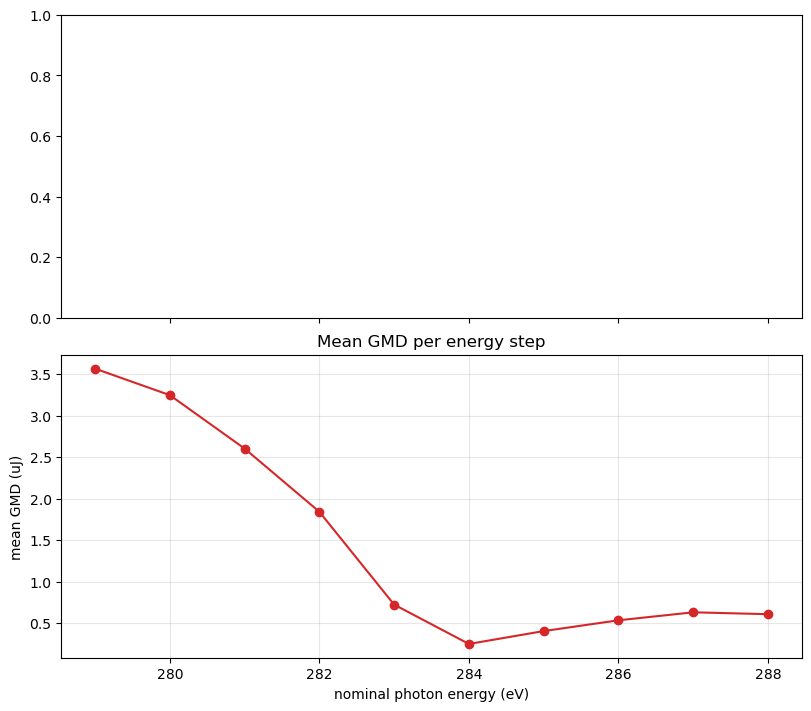

In [108]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, constrained_layout=True)

# axes[0].plot(nominal_energies, n_shots, 'o-', color='tab:blue', label='shots')
# axes[0].plot(nominal_energies, n_selected_trains, 's--', color='tab:orange', label='selected trains')
# axes[0].set_ylabel('count')
# axes[0].set_title(f'Run {RUN_NO}: sampling per photon energy')
# axes[0].grid(alpha=0.3)
# axes[0].legend()

axes[1].plot(nominal_energies, mean_gmd, 'o-', color='tab:red')
axes[1].set_xlabel('nominal photon energy (eV)')
axes[1].set_ylabel('mean GMD (uJ)')
axes[1].set_title('Mean GMD per energy step')
axes[1].grid(alpha=0.3)

plt.show()


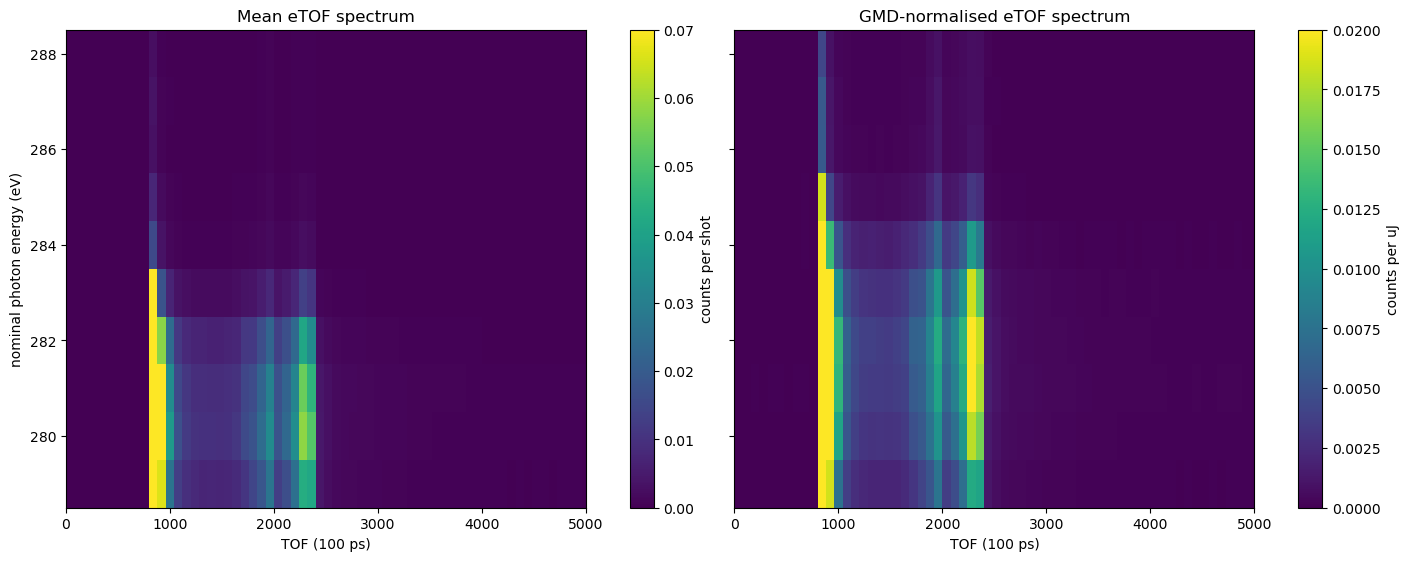

In [109]:
finite_raw = plot_mean_spec[np.isfinite(plot_mean_spec)]
finite_norm = plot_norm_spec[np.isfinite(plot_norm_spec)]
raw_vmax = np.nanpercentile(finite_raw, 99) if finite_raw.size else 1.0
norm_vmax = np.nanpercentile(finite_norm, 99) if finite_norm.size else 1.0

raw_vmax = 0.07
norm_vmax = 0.02

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True, constrained_layout=True)

pcm0 = axes[0].pcolormesh(
    plot_tof_edges,
    energy_mesh,
    plot_mean_spec,
    shading='auto',
    cmap='viridis',
    vmin=0.0,
    vmax=raw_vmax,
)
fig.colorbar(pcm0, ax=axes[0], label='counts per shot')
axes[0].set_title('Mean eTOF spectrum')
axes[0].set_xlabel('TOF (100 ps)')
axes[0].set_ylabel('nominal photon energy (eV)')
axes[0].set_xlim(*TOF_XLIM)

pcm1 = axes[1].pcolormesh(
    plot_tof_edges,
    energy_mesh,
    plot_norm_spec,
    shading='auto',
    cmap='viridis',
    vmin=0.0,
    vmax=norm_vmax,
)
fig.colorbar(pcm1, ax=axes[1], label='counts per uJ')
axes[1].set_title('GMD-normalised eTOF spectrum')
axes[1].set_xlabel('TOF (100 ps)')
axes[1].set_xlim(*TOF_XLIM)

plt.show()


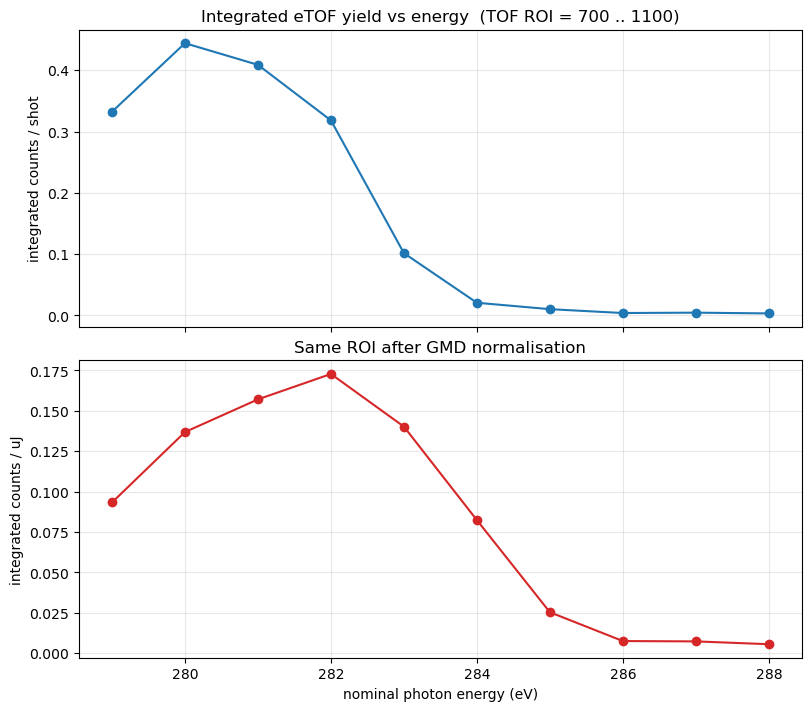

In [110]:
TOF_ROI = (700,1100)

tof_lo, tof_hi = TOF_ROI
roi_mask = (plot_tof_centers >= tof_lo) & (plot_tof_centers <= tof_hi)
if not np.any(roi_mask):
    raise ValueError('TOF_ROI selects no bins.')

yield_raw = np.nansum(plot_mean_spec[:, roi_mask], axis=1)
yield_norm = np.nansum(plot_norm_spec[:, roi_mask], axis=1)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, constrained_layout=True)

axes[0].plot(nominal_energies, yield_raw, 'o-', color='tab:blue')
axes[0].set_ylabel('integrated counts / shot')
axes[0].set_title(f'Integrated eTOF yield vs energy  (TOF ROI = {tof_lo:.0f} .. {tof_hi:.0f})')
axes[0].grid(alpha=0.3)

axes[1].plot(nominal_energies, yield_norm, 'o-', color='tab:red')
axes[1].set_xlabel('nominal photon energy (eV)')
axes[1].set_ylabel('integrated counts / uJ')
axes[1].set_title('Same ROI after GMD normalisation')
axes[1].grid(alpha=0.3)

plt.show()


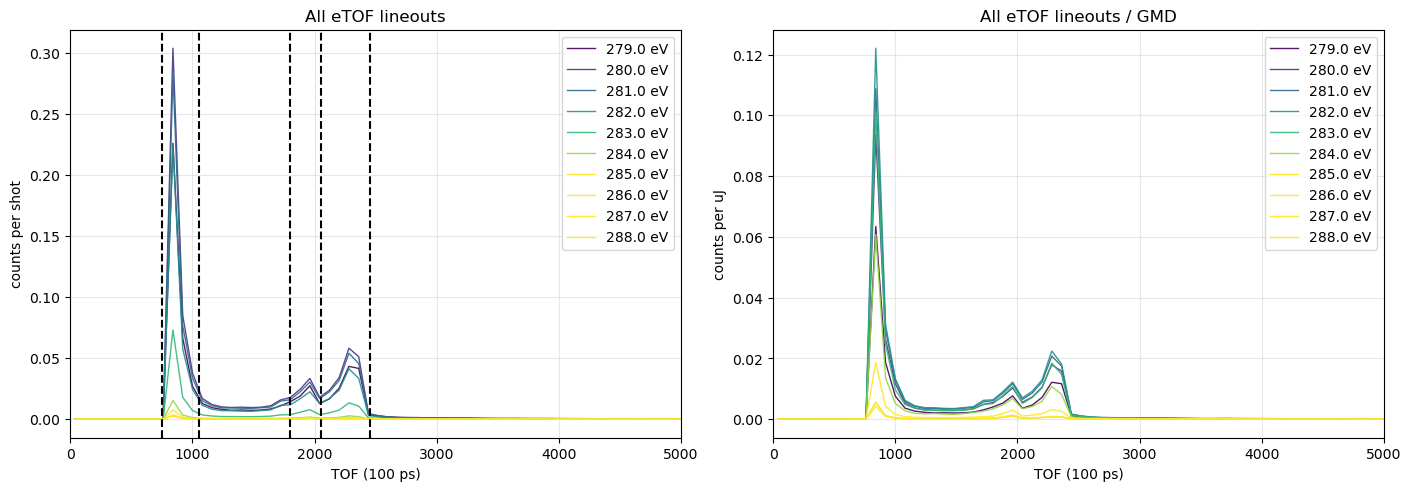

In [111]:
line_idx = np.arange(len(nominal_energies))
colors = plt.cm.viridis(np.linspace(0.0, 1.5, len(line_idx)))
colors = plt.cm.viridis(np.linspace(0.0, 1.5, len(line_idx)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, constrained_layout=True)

for color, idx in zip(colors, line_idx):
    label = fmt_energy(nominal_energies[idx])
    axes[0].plot(plot_tof_centers, plot_mean_spec[idx], color=color, lw=1.0, alpha=0.9, label = label)
    axes[1].plot(plot_tof_centers, plot_norm_spec[idx], color=color, lw=1.0, alpha=0.9, label = label)

axes[0].set_title('All eTOF lineouts')
axes[0].set_xlabel('TOF (100 ps)')
axes[0].set_ylabel('counts per shot')
axes[0].set_xlim(*TOF_XLIM)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[0].axvline(750, linestyle = '--', color = 'black')
axes[0].axvline(1050, linestyle = '--', color = 'black')

axes[0].axvline(1800, linestyle = '--', color = 'black')
axes[0].axvline(2050, linestyle = '--', color = 'black')
axes[0].axvline(2450, linestyle = '--', color = 'black')

axes[1].set_title('All eTOF lineouts / GMD')
axes[1].set_xlabel('TOF (100 ps)')
axes[1].set_ylabel('counts per uJ')
axes[1].set_xlim(*TOF_XLIM)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.show()

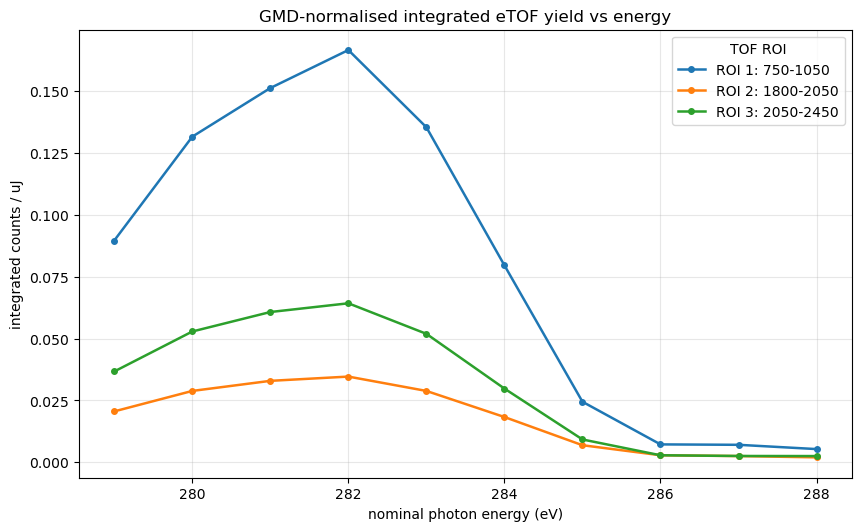

In [112]:
ROI_SPECS = [
    ("ROI 1: 750-1050", (750, 1050)),
    ("ROI 2: 1800-2050", (1800, 2050)),
    ("ROI 3: 2050-2450", (2050, 2450)),
]

fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)

for label, (tof_lo, tof_hi) in ROI_SPECS:
    roi_mask = (plot_tof_centers >= tof_lo) & (plot_tof_centers <= tof_hi)
    if not np.any(roi_mask):
        raise ValueError(f'{label} selects no bins.')

    yield_norm = np.nansum(plot_norm_spec[:, roi_mask], axis=1)
    ax.plot(nominal_energies, yield_norm, 'o-', lw=1.8, ms=4, label=label)

ax.set_xlabel('nominal photon energy (eV)')
ax.set_ylabel('integrated counts / uJ')
ax.set_title('GMD-normalised integrated eTOF yield vs energy')
ax.grid(alpha=0.3)
ax.legend(title='TOF ROI')

plt.show()

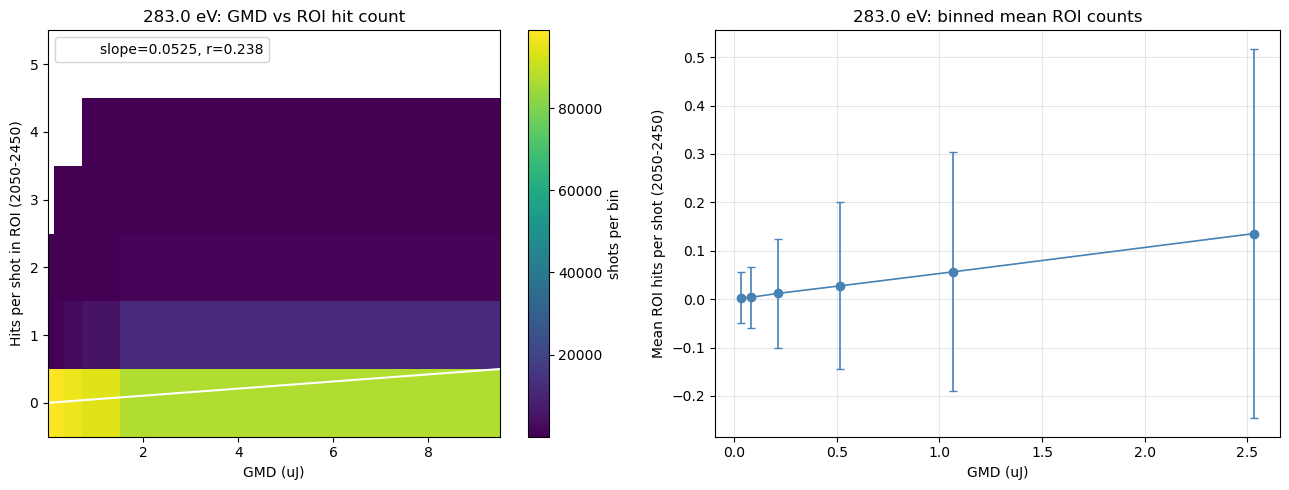

selected energy : 283.00 eV
selected shots  : 608828
unique trains   : 6028


In [113]:
energy_idx = int(np.abs(nominal_energies - SELECTED_ENERGY).argmin())
energy_sel = nominal_energies[energy_idx]
n_sel = int(n_shots[energy_idx])

tofs_sel = tofs_e[energy_idx, :n_sel]
gmd_sel = gmd[energy_idx, :n_sel]
bunch_sel = bunch_index[energy_idx, :n_sel]
train_sel = train_id[energy_idx, :n_sel]

counts_roi = counts_in_window_per_shot(tofs_sel, tof_lo, tof_hi)
good = np.isfinite(gmd_sel) & (gmd_sel > 0)
x = gmd_sel[good]
y = counts_roi[good]

if x.size == 0:
    raise ValueError('No finite positive GMD values for the selected energy.')

gmd_edges = percentile_bin_edges(x, GMD_N_BINS)
if gmd_edges.size < 2:
    raise ValueError('GMD values are too concentrated to build percentile bins.')

bin_idx = np.digitize(x, gmd_edges) - 1
bin_idx = np.clip(bin_idx, 0, len(gmd_edges) - 2)
gmd_bin_centres = 0.5 * (gmd_edges[:-1] + gmd_edges[1:])
mean_hits = np.array([np.nanmean(y[bin_idx == b]) if np.any(bin_idx == b) else np.nan for b in range(len(gmd_bin_centres))])
std_hits = np.array([np.nanstd(y[bin_idx == b]) if np.any(bin_idx == b) else np.nan for b in range(len(gmd_bin_centres))])
mean_gmd_bin = np.array([np.nanmean(x[bin_idx == b]) if np.any(bin_idx == b) else np.nan for b in range(len(gmd_bin_centres))])

r = float(np.corrcoef(x, y)[0, 1]) if x.size > 1 else np.nan
slope, intercept = np.polyfit(x, y, 1) if x.size > 1 else (np.nan, np.nan)
x_line = np.linspace(np.nanmin(x), np.nanmax(x), 100)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5))

h = ax.hist2d(x, y, bins=[gmd_edges, np.arange(int(np.nanmax(y)) + 3) - 0.5], cmap='viridis', cmin=1)
fig.colorbar(h[3], ax=ax, label='shots per bin')
if np.isfinite(slope):
    ax.plot(x_line, slope * x_line + intercept, color='white', lw=1.5, label=f'slope={slope:.3g}, r={r:.3f}')
ax.set_xlabel('GMD (uJ)')
ax.set_ylabel(f'Hits per shot in ROI ({tof_lo:.0f}-{tof_hi:.0f})')
ax.set_title(f'{energy_sel:.1f} eV: GMD vs ROI hit count')
ax.legend(loc='upper left', framealpha=0.85)

ax2.errorbar(mean_gmd_bin, mean_hits, yerr=std_hits, fmt='o-', color='steelblue', capsize=3, lw=1.2)
ax2.set_xlabel('GMD (uJ)')
ax2.set_ylabel(f'Mean ROI hits per shot ({tof_lo:.0f}-{tof_hi:.0f})')
ax2.set_title(f'{energy_sel:.1f} eV: binned mean ROI counts')
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f'selected energy : {energy_sel:.2f} eV')
print(f'selected shots  : {n_sel}')
print(f'unique trains   : {np.unique(train_sel[train_sel >= 0]).size}')


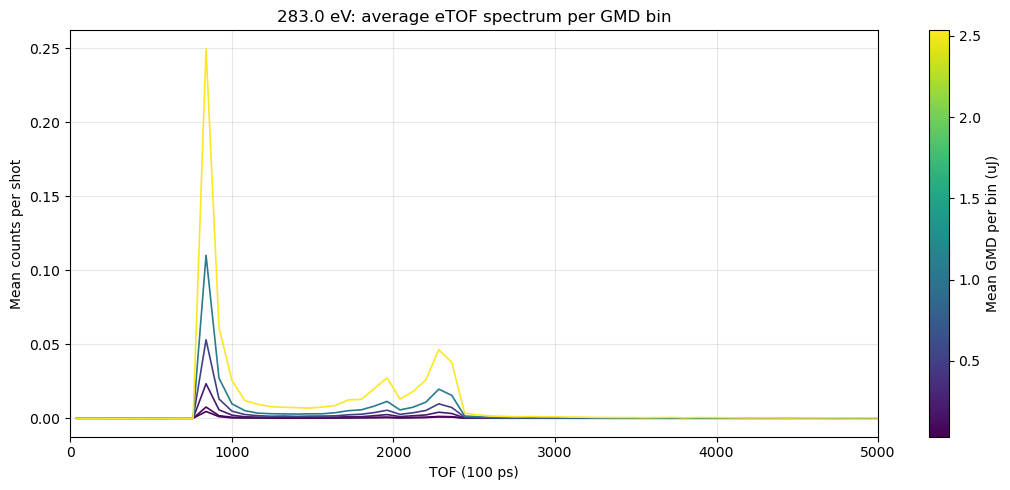

In [114]:
good_idx = np.flatnonzero(good)
shot_bin_of_good = np.full(n_sel, -1, dtype=int)
shot_bin_of_good[good_idx] = np.digitize(gmd_sel[good], gmd_edges) - 1
shot_bin_of_good = np.clip(shot_bin_of_good, -1, len(gmd_edges) - 2)

spec_by_gmd = np.full((len(gmd_edges) - 1, len(tof_centers)), np.nan, dtype=np.float64)
for b in range(len(gmd_edges) - 1):
    mask = shot_bin_of_good == b
    if not np.any(mask):
        continue
    spec_by_gmd[b] = mean_spectrum_per_shot(tofs_sel[mask], tof_edges)

plot_spec_by_gmd = rebin_last_axis(spec_by_gmd, TOF_REBIN)
norm = mcolors.Normalize(vmin=float(np.nanmin(mean_gmd_bin)), vmax=float(np.nanmax(mean_gmd_bin)))
cmap = plt.cm.viridis

fig, ax = plt.subplots(figsize=(11, 5))
for cent, spec in zip(mean_gmd_bin, plot_spec_by_gmd):
    if not np.all(np.isnan(spec)):
        ax.plot(plot_tof_centers, spec, color=cmap(norm(cent)), lw=1.2)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=ax, label='Mean GMD per bin (uJ)')
ax.set_xlabel('TOF (100 ps)')
ax.set_ylabel('Mean counts per shot')
ax.set_title(f'{energy_sel:.1f} eV: average eTOF spectrum per GMD bin')
ax.set_xlim(*TOF_XLIM)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


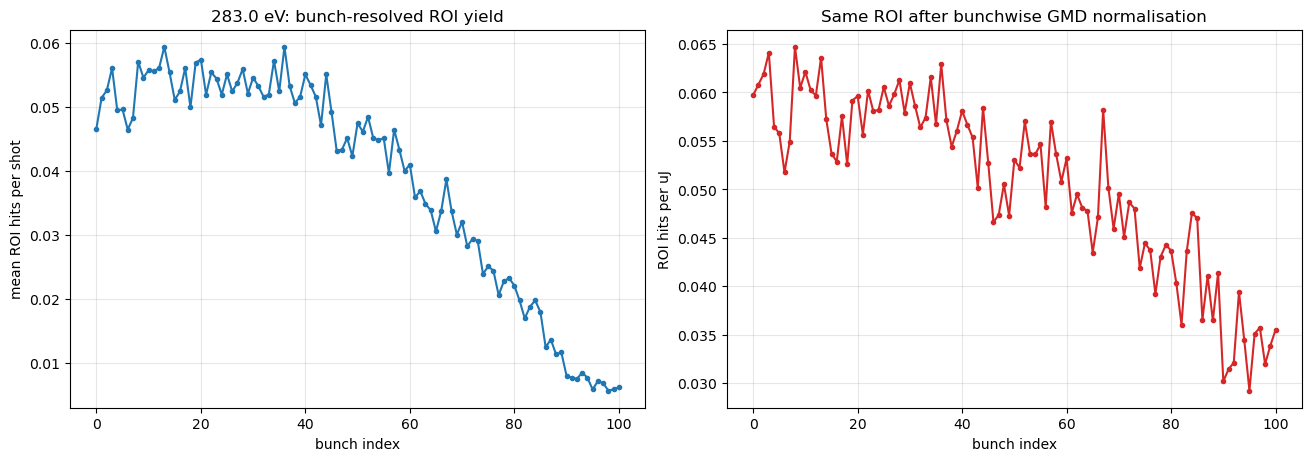

In [115]:
bunch_vals = bunch_sel.astype(np.int64)
roi_mean_bunch = np.full(signal_bunch_indices.shape, np.nan, dtype=np.float64)
roi_norm_bunch = np.full(signal_bunch_indices.shape, np.nan, dtype=np.float64)

for j, b in enumerate(signal_bunch_indices):
    mask = bunch_vals == int(b)
    if not np.any(mask):
        continue
    roi_mean_bunch[j] = np.nanmean(counts_roi[mask])
    good_mask = mask & np.isfinite(gmd_sel) & (gmd_sel > 0)
    if np.any(good_mask):
        roi_norm_bunch[j] = np.nansum(counts_roi[good_mask]) / np.sum(gmd_sel[good_mask])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axes[0].plot(signal_bunch_indices, roi_mean_bunch, 'o-', ms=3)
axes[0].set_xlabel('bunch index')
axes[0].set_ylabel('mean ROI hits per shot')
axes[0].set_title(f'{energy_sel:.1f} eV: bunch-resolved ROI yield')
axes[0].grid(alpha=0.3)

axes[1].plot(signal_bunch_indices, roi_norm_bunch, 'o-', ms=3, color='tab:red')
axes[1].set_xlabel('bunch index')
axes[1].set_ylabel('ROI hits per uJ')
axes[1].set_title('Same ROI after bunchwise GMD normalisation')
axes[1].grid(alpha=0.3)

plt.show()


## Notes

- This is a static energy scan, so there is no delay axis in this file.
- GMD normalisation here is done as `sum(counts) / sum(GMD)` over the selected shots, not as `mean(counts / GMD)`.
- Because the file is shot-resolved, you can add stricter GMD cuts, bunch cuts, or custom TOF ROIs later without rerunning the writer.
